#https://snap.stanford.edu/data/CollegeMsg.html

   source  target  timestamp            datetime
0     582     364          0 1970-01-01 00:00:00
1     168     472       2797 1970-01-01 00:46:37
2     168     912       3304 1970-01-01 00:55:04
3       2     790       4523 1970-01-01 01:15:23
4       2     322       7926 1970-01-01 02:12:06
Número de interações temporais: 332,334
Número de nós: 986

Graph for first week
--------------------
Nodes: 581
Edges: 1501

Top 10 nodes by degree
  159  0.0810
  738  0.0672
  987  0.0534
  569  0.0534
  629  0.0517
  540  0.0466
  915  0.0431
  335  0.0431
  850  0.0431
   90  0.0414

Top 10 nodes by betweenness
  159  0.1707
   90  0.0778
  738  0.0774
  569  0.0621
  629  0.0586
  607  0.0505
  951  0.0468
  915  0.0462
  987  0.0458
  362  0.0451

Top 10 nodes by closeness
  159  0.3643
  607  0.3347
  923  0.3312
   90  0.3255
  915  0.3243
  629  0.3226
  569  0.3217
  334  0.3217
  692  0.3215
  687  0.3183

Top 10 nodes by eigenvector
  159  0.3425
  629  0.2171
  915  0.2054
  334  0.1

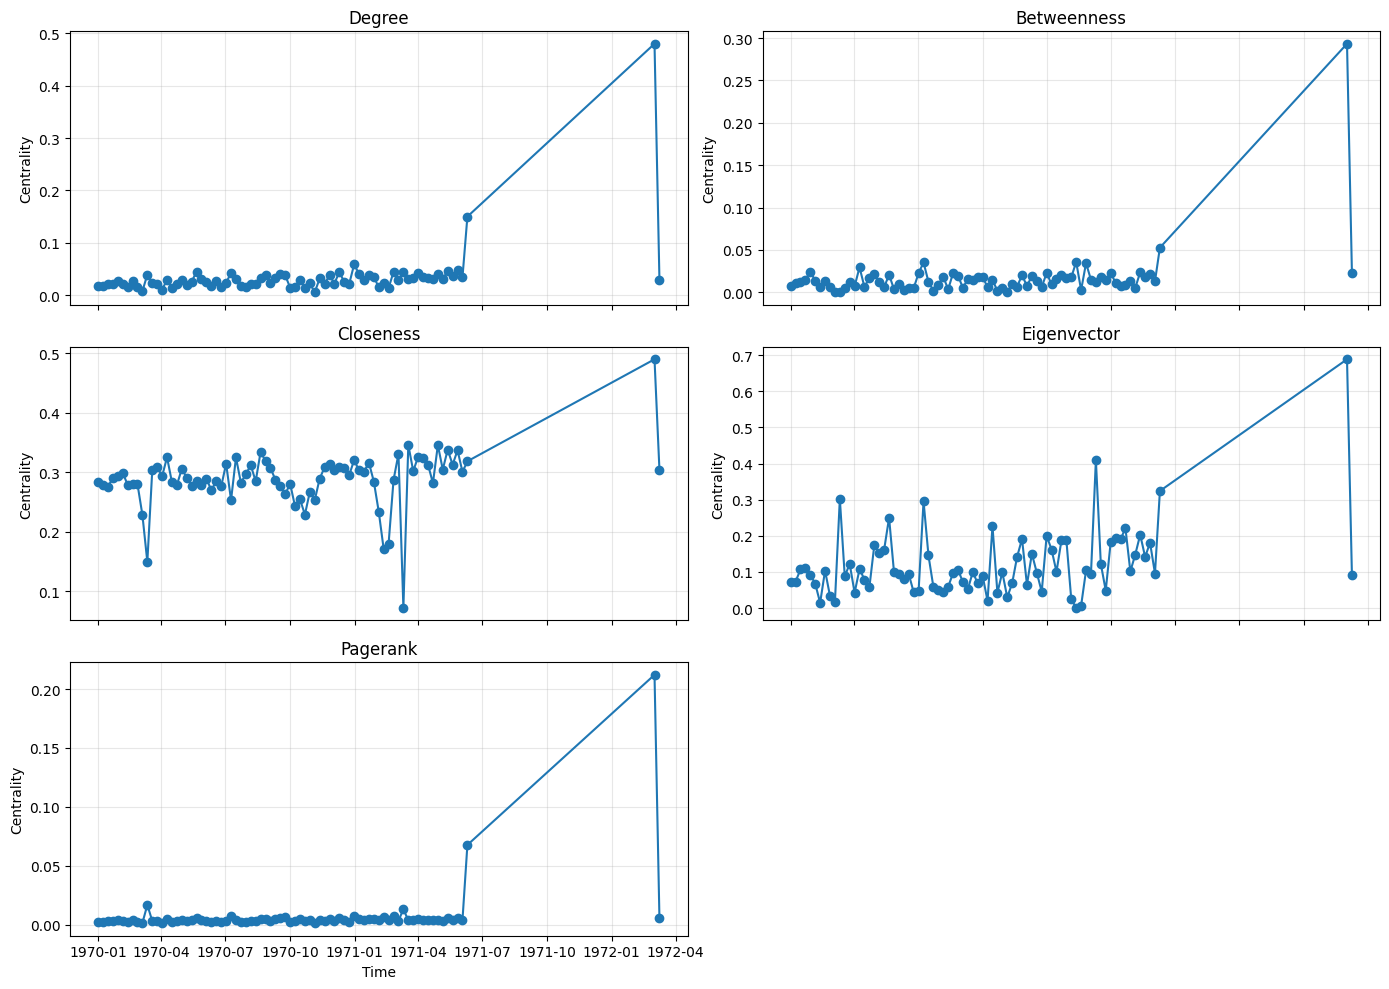

In [1]:
import gzip
import io
import urllib.request
from datetime import datetime

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# Obtendo o banco de dados direto da URL
# ============================================================

URL = "https://snap.stanford.edu/data/email-Eu-core-temporal.txt.gz"

with urllib.request.urlopen(URL) as response:
    data = gzip.decompress(response.read()).decode("utf-8")


# ============================================================
# Lendo as arestas temporais Read the temporal edges
# ============================================================

edges = []

for line in io.StringIO(data):
    line = line.strip()

    # Ignorar as linhas de comentários
    if not line or line.startswith("#"):
        continue

    src, dst, timestamp = map(int, line.split())

    edges.append({
        "source": src,
        "target": dst,
        "timestamp": timestamp
    })

df = pd.DataFrame(edges)

# Convertendo timestamps para para datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="s")

print(df.head())
print(f"Número de interações temporais: {len(df):,}")
print(f"Número de nós: {len(set(df.source) | set(df.target)):,}")



# ============================================================
# Função para construir um grafo para a janela de tempo
# ============================================================

def graph_at_time(df, start, end):
    """
    Constrói o grafo contendo todas as interações durante o período de tempo considerado
    """

    mask = (df["datetime"] >= start) & (df["datetime"] < end)

    window = df.loc[mask]

    G = nx.Graph()

    for _, row in window.iterrows():
        G.add_edge(row["source"], row["target"])

    return G


# ============================================================
# Medidas de centralidade para o grafo em um momento do tempo
# ============================================================

def centralities_at_time(G):
    """
    Calculando as medidas de centralidade
    """

    results = {}

    # Degree centrality
    results["degree"] = nx.degree_centrality(G)

    # Betweenness centrality
    results["betweenness"] = nx.betweenness_centrality(G)

    # Closeness centrality
    results["closeness"] = nx.closeness_centrality(G)

    # Eigenvector centrality

    try:
        results["eigenvector"] = nx.eigenvector_centrality(
            G,
            max_iter=1000
        )
    except nx.PowerIterationFailedConvergence:
        results["eigenvector"] = {}

    # PageRank
    results["pagerank"] = nx.pagerank(G)

    return results


# ============================================================
# Calculando as medidas de centralidade para uma semana
# ============================================================

start = df["datetime"].min()
end = start + pd.Timedelta(days=7)

G = graph_at_time(df, start, end)

print("\nGraph for first week")
print("--------------------")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

centralities = centralities_at_time(G)


# ============================================================
# Mostrando os 10 nós com maiores medidas de centralidade
# ============================================================

for measure, values in centralities.items():

    print(f"\nTop 10 nodes by {measure}")

    top = sorted(
        values.items(),
        key=lambda x: x[1],
        reverse=True
    )[:10]

    for node, score in top:
        print(f"{node:5d}  {score:.4f}")


# ============================================================
#  Calculando as medidas de centralidade em múltiplos momentos (tempo)
# ============================================================

window_size = pd.Timedelta(days=7)

start = df["datetime"].min()
last = df["datetime"].max()

temporal_results = []

current = start

while current < last:

    next_time = current + window_size

    G = graph_at_time(
        df,
        current,
        next_time
    )

    # Skip completely empty windows
    if G.number_of_nodes() > 0:

        C = centralities_at_time(G)

        # Store the centrality of every node
        nodes = set().union(*[
            set(values.keys())
            for values in C.values()
        ])

        for node in nodes:

            temporal_results.append({
                "time": current,
                "node": node,
                "degree": C["degree"].get(node, 0),
                "betweenness": C["betweenness"].get(node, 0),
                "closeness": C["closeness"].get(node, 0),
                "eigenvector": C["eigenvector"].get(node, 0),
                "pagerank": C["pagerank"].get(node, 0),
            })

    current = next_time


temporal_centrality = pd.DataFrame(temporal_results)

print("\nTemporal centrality")
print(temporal_centrality.head())


# ============================================================
# Medidas de centralidade de uma pessoa variando com o tempo
# ============================================================


#pega o nó que aparece com mais frequência no dataframe de centralidade temporal
node = temporal_centrality["node"].value_counts().index[0]

person = temporal_centrality[
    temporal_centrality["node"] == node
].sort_values("time")

print(f"\nCentrality evolution for node {node}")
print(person)


# ============================================================
#  Plot medidas de centralidade temporais
# ============================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 10),
    sharex=True
)

measures = [
    "degree",
    "betweenness",
    "closeness",
    "eigenvector",
    "pagerank"
]

for ax, measure in zip(axes.flat, measures):

    ax.plot(
        person["time"],
        person[measure],
        marker="o"
    )

    ax.set_title(measure.capitalize())
    ax.set_ylabel("Centrality")
    ax.grid(alpha=0.3)

axes[-1, 0].set_xlabel("Time")
axes[-1, 1].set_xlabel("Time")

# Hide the unused sixth subplot
axes[-1, 1].set_visible(False)

plt.tight_layout()
plt.show()
